**Ekstraksi Dataset**

In [5]:
from google.colab import drive
drive.mount('/content/drive')

# Salin file ZIP dari Google Drive ke lingkungan lokal Colab
!cp "/content/drive/MyDrive/dataset_raw.zip" .

# Ekstrak file ZIP tersebut
!unzip dataset_raw.zip -d .
print("Dataset berhasil diekstrak!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archive:  dataset_raw.zip
replace ./train/bola_basket/bola_0001.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: ./train/bola_basket/bola_0001.jpg  
  inflating: ./train/bola_basket/bola_0002.jpg  
  inflating: ./train/bola_basket/bola_0003.jpg  
  inflating: ./train/bola_basket/bola_0005.jpg  
  inflating: ./train/bola_basket/bola_0006.jpg  
  inflating: ./train/bola_basket/bola_0007.jpg  
  inflating: ./train/bola_basket/bola_0009.jpg  
  inflating: ./train/bola_basket/bola_0010.jpg  
  inflating: ./train/bola_basket/bola_0011.jpg  
  inflating: ./train/bola_basket/bola_0012.jpg  
  inflating: ./train/bola_basket/bola_0013.jpg  
  inflating: ./train/bola_basket/bola_0014.jpg  
  inflating: ./train/bola_basket/bola_0015.jpg  
  inflating: ./train/bola_basket/bola_0016.jpg  
  inflating: ./train/bola_basket/bola_0017.jpg  
  inflating: ./train/bola_b

**Import Library & Setup Device**

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
from sklearn.metrics import accuracy_score, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import random
import time
import os
import csv

random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")
print("Direktori kelas:", os.listdir("/content/train"))

Menggunakan device: cuda:0
Direktori kelas: ['basket', 'bola_basket']


**Transformasi Gambar & Pembuatan metadata.csv**

In [7]:
basic_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

img_dataset = ImageFolder("/content/train", basic_transforms)
print(f"Kelas ditemukan: {img_dataset.classes}")
print(f"Total seluruh citra: {len(img_dataset)}")

Kelas ditemukan: ['basket', 'bola_basket']
Total seluruh citra: 97


In [8]:
import os
import csv

# Tentukan direktori dataset train Anda
dataset_dir = "/content/train"
csv_file_path = "/content/metadata.csv"

# Membuka file CSV untuk ditulis
with open(csv_file_path, mode='w', newline='', encoding='utf-8') as file:
    writer = csv.writer(file)
    # Menulis header kolom
    writer.writerow(["filename", "label"])

    # Menelusuri folder kelas dan file gambarnya
    for class_name in os.listdir(dataset_dir):
        class_path = os.path.join(dataset_dir, class_name)
        if os.path.isdir(class_path):
            for img_name in os.listdir(class_path):
                # Format isi: path relatif/nama file dan nama kelasnya
                writer.writerow([f"{class_name}/{img_name}", class_name])

print(f"File '{csv_file_path}' berhasil dibuat!")

File '/content/metadata.csv' berhasil dibuat!


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Pembagian Data (Train, Validation, Test)**

In [10]:
generator = torch.Generator().manual_seed(42)

train_size = int(0.7 * len(img_dataset))
val_size = int(0.15 * len(img_dataset))
test_size = len(img_dataset) - train_size - val_size

train_set, val_set, test_set = random_split(img_dataset, [train_size, val_size, test_size], generator=generator)

train_dataloader = DataLoader(train_set, batch_size=16, shuffle=True)
val_dataloader = DataLoader(val_set, batch_size=16, shuffle=False)
test_dataloader = DataLoader(test_set, batch_size=16, shuffle=False)

print(f"Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)}")

Train: 67 | Val: 14 | Test: 16


**Definisi Arsitektur ResNet-18**

In [11]:
class ResNet18Model(nn.Module):
    def __init__(self, mode='feature_extraction', num_classes=2):
        super(ResNet18Model, self).__init__()

        if mode == 'feature_extraction':
            self.resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
            for param in self.resnet.parameters():
                param.requires_grad = False
        elif mode == 'fine_tuning':
            self.resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
            for param in self.resnet.parameters():
                param.requires_grad = False
            for param in self.resnet.layer4.parameters():
                param.requires_grad = True
        else: # scratch
            self.resnet = models.resnet18(weights=None)

        # Sesuaikan layer akhir dengan jumlah kelas Anda (basket & bola_basket = 2)
        self.resnet.fc = nn.Linear(self.resnet.fc.in_features, num_classes)

    def forward(self, x):
        return self.resnet(x)

**Inisialisasi Model**

In [12]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# Inisialisasi model (pilih mode: 'feature_extraction', 'fine_tuning', atau 'scratch')
model = ResNet18Model(mode='fine_tuning', num_classes=len(img_dataset.classes))
model.to(device)

# Cetak struktur model untuk memastikan semuanya sudah benar
print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 193MB/s]


ResNet18Model(
  (resnet): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, trac

**Fungsi Training & Evaluasi**

In [13]:
def train_model(dataloader, model, loss_fn, optimizer):
    pred_list = torch.tensor([]).to(device)
    true_list = torch.tensor([]).to(device)
    losses = []

    model.train()
    for d in tqdm(dataloader):
        inputs, labels = d
        inputs, labels = inputs.to(device), labels.to(device)

        outputs = model(inputs)
        logits = torch.argmax(outputs, dim=1)

        pred_list = torch.concatenate([pred_list, logits])
        true_list = torch.concatenate([true_list, labels])

        loss = loss_fn(outputs, labels)
        losses.append(loss.item())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    avg_loss = torch.mean(torch.tensor(losses)).item()
    return avg_loss, true_list.detach(), pred_list.detach()

def eval_model(dataloader, model, loss_fn):
    pred_list = torch.tensor([]).to(device)
    true_list = torch.tensor([]).to(device)
    losses = []

    model.eval()
    with torch.no_grad():
        for d in tqdm(dataloader):
            inputs, labels = d
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            logits = torch.argmax(outputs, dim=1)

            pred_list = torch.concatenate([pred_list, logits])
            true_list = torch.concatenate([true_list, labels])

            loss = loss_fn(outputs, labels)
            losses.append(loss.item())

    avg_loss = torch.mean(torch.tensor(losses)).item()
    return avg_loss, true_list.detach(), pred_list.detach()

**Menjalankan Training & Menyimpan File Bobot Model (.pth)**

In [14]:
EPOCHS = 20
model = ResNet18Model(mode='fine_tuning', num_classes=len(img_dataset.classes)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)

history = {
    "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": []
}

min_loss = 999
best_state = None

for i in range(EPOCHS):
    print(f"\n--- Training Epoch {i+1}/{EPOCHS} ---")

    # Train
    train_loss, t_true, t_pred = train_model(train_dataloader, model, loss_fn, optimizer)
    train_acc = accuracy_score(t_true.cpu().numpy(), t_pred.cpu().numpy())

    # Validation
    val_loss, v_true, v_pred = eval_model(val_dataloader, model, loss_fn)
    val_acc = accuracy_score(v_true.cpu().numpy(), v_pred.cpu().numpy())

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

    if val_loss < min_loss:
        min_loss = val_loss
        best_state = model.state_dict()

# Load bobot terbaik
model.load_state_dict(best_state)


--- Training Epoch 1/20 ---


100%|██████████| 1/1 [00:00<00:00,  4.69it/s]


Train Loss: 0.3968 | Train Acc: 0.7313
Val Loss: 0.2522 | Val Acc: 0.8571

--- Training Epoch 2/20 ---


100%|██████████| 1/1 [00:00<00:00,  5.38it/s]


Train Loss: 0.0267 | Train Acc: 1.0000
Val Loss: 0.4686 | Val Acc: 0.8571

--- Training Epoch 3/20 ---


...

100%|██████████| 1/1 [00:00<00:00,  5.27it/s]


Train Loss: 0.0141 | Train Acc: 1.0000
Val Loss: 0.0035 | Val Acc: 1.0000

--- Training Epoch 20/20 ---


100%|██████████| 1/1 [00:00<00:00,  5.34it/s]


Train Loss: 0.0080 | Train Acc: 1.0000
Val Loss: 0.0044 | Val Acc: 1.0000


<All keys matched successfully>

**Visualisasi Grafik Loss & Akurasi**

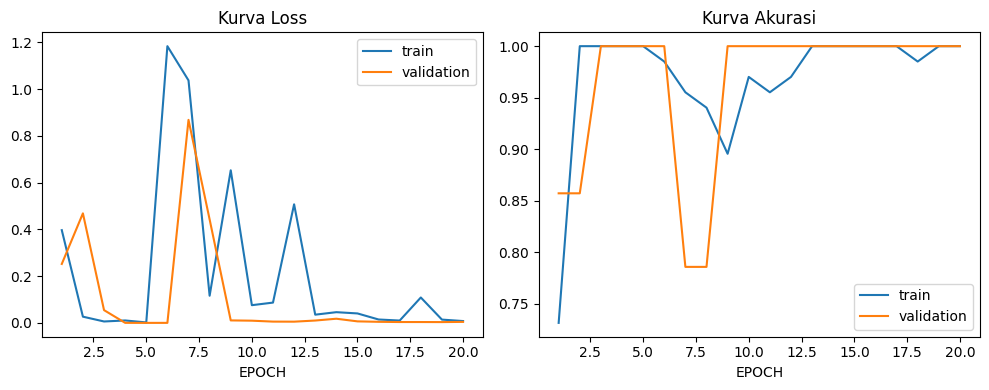

In [15]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.lineplot(x=range(1, EPOCHS+1), y=history['train_loss'], label='train')
sns.lineplot(x=range(1, EPOCHS+1), y=history['val_loss'], label='validation')
plt.xlabel("EPOCH")
plt.title("Kurva Loss")

plt.subplot(1, 2, 2)
sns.lineplot(x=range(1, EPOCHS+1), y=history['train_acc'], label='train')
sns.lineplot(x=range(1, EPOCHS+1), y=history['val_acc'], label='validation')
plt.xlabel("EPOCH")
plt.title("Kurva Akurasi")
plt.tight_layout()
plt.show()

**Evaluasi Akhir pada Test Set**

In [16]:
# Memuat bobot terbaik hasil training sebelumnya
model.load_state_dict(best_state)

# Melakukan evaluasi pada data test
loss, true_list, pred_list = eval_model(test_dataloader, model, loss_fn)

# Menghitung akurasi akhir
acc = accuracy_score(true_list.cpu().numpy(), pred_list.cpu().numpy())

# Menampilkan laporan klasifikasi lengkap
print("ResNet18")
print(classification_report(true_list.cpu().numpy(), pred_list.cpu().numpy()))
print(f"val loss : {loss}, val acc : {acc}")

100%|██████████| 1/1 [00:00<00:00,  3.84it/s]

ResNet18
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00        10
         1.0       1.00      1.00      1.00         6

    accuracy                           1.00        16
   macro avg       1.00      1.00      1.00        16
weighted avg       1.00      1.00      1.00        16

val loss : 0.015089832246303558, val acc : 1.0


**Visualisasi Hasil Prediksi Gambar**

In [17]:
from google.colab import files
import os

# Daftar file yang ingin diunduh otomatis (pastikan nama jalurnya sesuai)
files_to_download = [
    '/content/metadata.csv',
    '/content/hasil_prediksi_test.jpg',
    '/content/hasil_training/resnet18_fine_tuning.pth' # Sesuaikan path file .pth Anda jika berbeda
]

for file_path in files_to_download:
    if os.path.exists(file_path):
        print(f"Mengunduh: {file_path}")
        files.download(file_path)
    else:
        print(f"File tidak ditemukan: {file_path} (Pastikan sel kodenya sudah pernah dijalankan sebelumnya)")

Mengunduh: /content/metadata.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

File tidak ditemukan: /content/hasil_prediksi_test.jpg (Pastikan sel kodenya sudah pernah dijalankan sebelumnya)
File tidak ditemukan: /content/hasil_training/resnet18_fine_tuning.pth (Pastikan sel kodenya sudah pernah dijalankan sebelumnya)


In [18]:
import os
import torch

# Membuat foldernya dulu jika belum ada
os.makedirs('/content/hasil_training', exist_ok=True)

# Menyimpan model (pastikan variabel 'best_state' sudah ada dari proses training sebelumnya)
if 'best_state' in globals():
    torch.save(best_state, '/content/hasil_training/resnet18_fine_tuning.pth')
    print("SUKSES: Model berhasil disimpan ke /content/hasil_training/resnet18_fine_tuning.pth")
else:
    print("ERROR: Jalankan sel training model terlebih dahulu agar variabel 'best_state' terbentuk!")

SUKSES: Model berhasil disimpan ke /content/hasil_training/resnet18_fine_tuning.pth


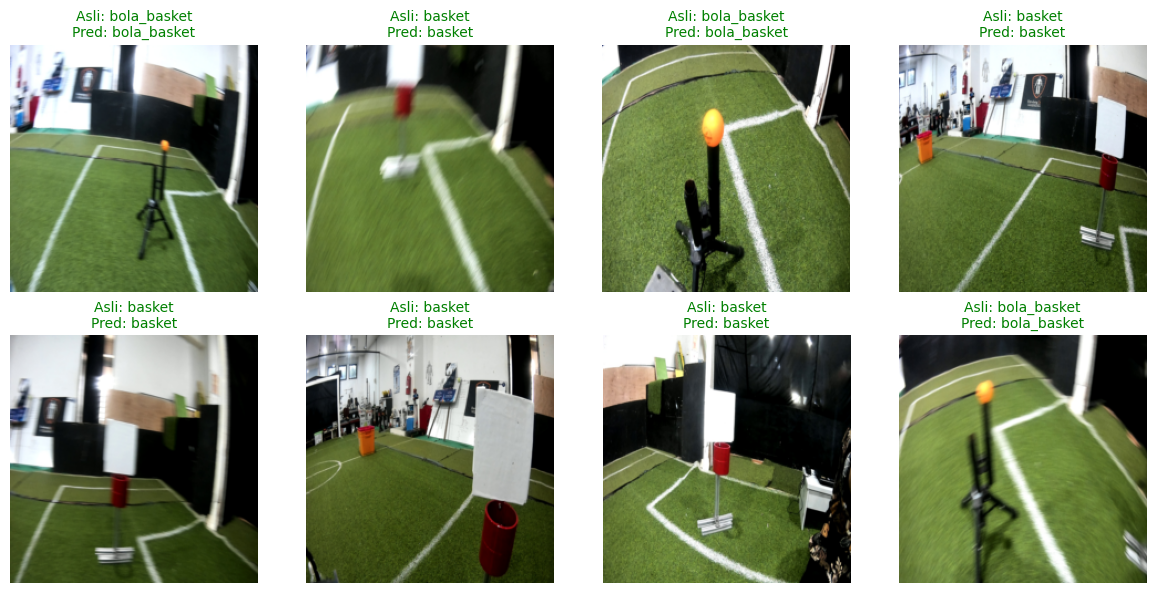

SUKSES: Gambar prediksi berhasil disimpan sebagai /content/hasil_prediksi_test.jpg


In [19]:
import matplotlib.pyplot as plt
import torch

model.eval()
class_names = img_dataset.classes  # ['basket', 'bola_basket']
images, labels = next(iter(test_dataloader))
images_dev = images.to(device)

with torch.no_grad():
    outputs = model(images_dev)
    _, preds = torch.max(outputs, 1)

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

plt.figure(figsize=(12, 6))
for i in range(min(8, len(images))):
    ax = plt.subplot(2, 4, i + 1)
    img = images[i].cpu() * std + mean
    img = torch.clamp(img, 0, 1)
    img = img.permute(1, 2, 0).numpy()

    plt.imshow(img)
    true_label = class_names[labels[i].item()]
    pred_label = class_names[preds[i].item()]
    color = 'green' if true_label == pred_label else 'red'

    ax.set_title(f"Asli: {true_label}\nPred: {pred_label}", color=color, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.savefig('/content/hasil_prediksi_test.jpg', dpi=300, bbox_inches='tight')
plt.show()
print("SUKSES: Gambar prediksi berhasil disimpan sebagai /content/hasil_prediksi_test.jpg")